INPUT REFERENCE
Path: F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_classes_aligned_to_s2_10m.tif
CRS: EPSG:3857
Shape: (3160, 4897)
Resolution: (10.0, 10.0)
Transform: | 10.00, 0.00, 4081450.00|
| 0.00,-10.00,-129210.00|
| 0.00, 0.00, 1.00|
NoData: None

Input value counts:


,value,count
0,0,7104088
1,1,2948725
2,2,3702102
3,3,472863
4,255,1246742



Source values: [0, 1, 2, 3, 255]
Declared raster NoData: None
Values treated as invalid/background: [0, 255]

AGGREGATION GRID
Scale factor: 8
Input shape: (3160, 4897)
Output shape: (395, 612)
Complete source area used: (3160, 4896)
Incomplete rows omitted at bottom: 0
Incomplete columns omitted at right: 1

OUTPUT GRID
Output resolution: (80.0, -80.0)
Output origin: (4081450.0, -129210.0)
Output unique labels: [-1  0  1]

BINARY REFERENCE AUDIT


,value,label,cell_count,percentage_of_output_grid
0,-1,Background / NoData,129137,53.419790
1,0,Non-informal,105183,43.510797
2,1,Informal built-up,7420,3.069413


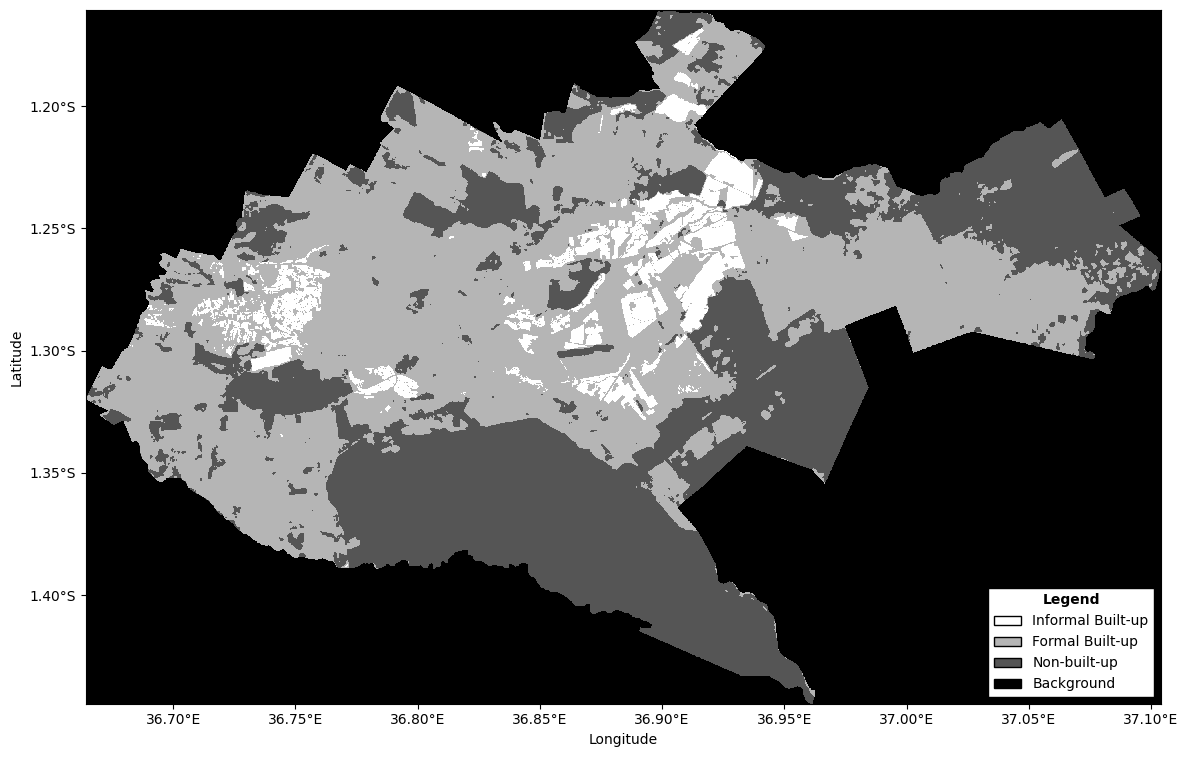

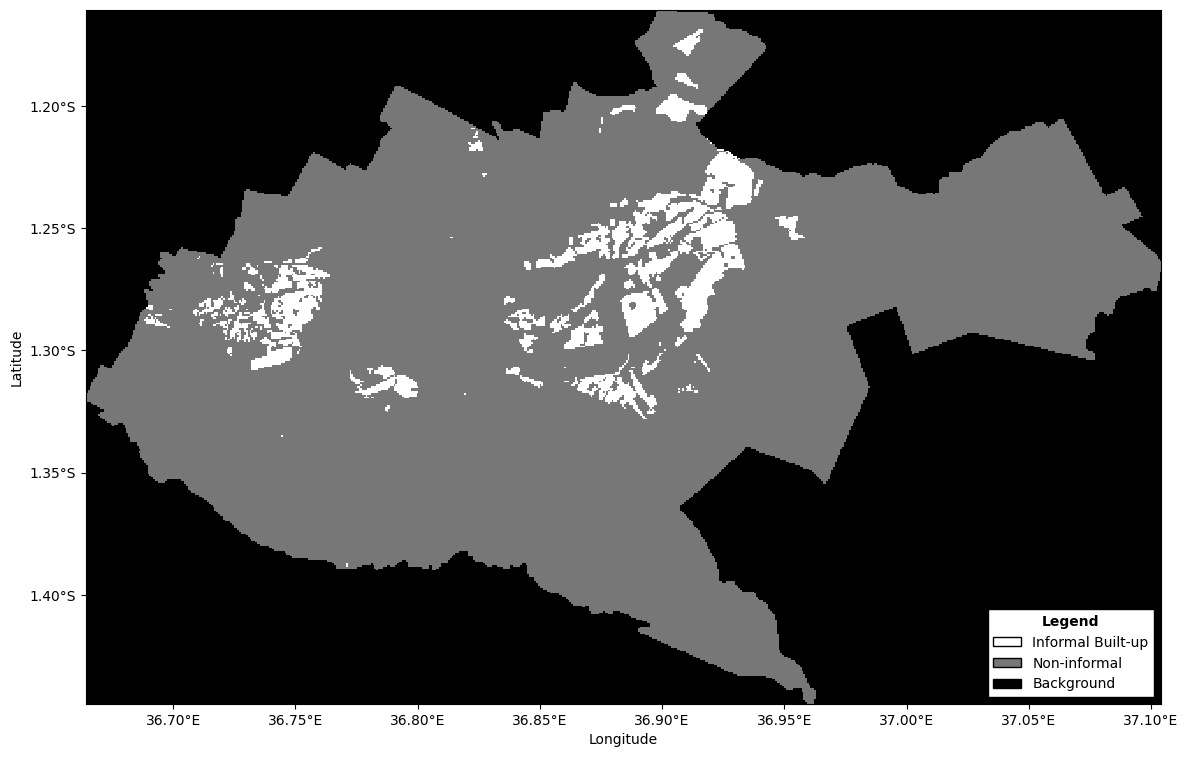


OUTPUT VERIFICATION
Binary 80 m reference:
  F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_binary_aligned_to_s2_80m.tif
  exists: True
Informal fraction:
  F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_informal_fraction_aligned_to_s2_80m.tif
  exists: True
Valid pixel count:
  F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_valid_pixel_count_aligned_to_s2_80m.tif
  exists: True
Original reference map:
  F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_classes_aligned_10m_map.png
  exists: True
Binary reference map:
  F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_binary_aligned_80m_map.png
  exists: True
Audit CSV:
  F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_80m_value_counts.csv
  exists: True

Binary raster CRS: EPSG:3857
Binary raster shape: (395, 612)
Binary ras

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
from affine import Affine
from rasterio.transform import array_bounds
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling,
)

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter


# ============================================================
# 1. PATHS
# ============================================================

ROOT_DIR = Path(
    r"F:\Master Research Thesis\Code\Mapping_Generation"
    r"\reference_alignment_v2"
)

# Use the aligned and clipped 10 m reference created in ArcGIS Pro.
INPUT_REFERENCE = (
    ROOT_DIR
    / "Nrb_reference_classes_aligned_to_s2_10m.tif"
)

OUTPUT_REFERENCE = (
    ROOT_DIR
    / "Nrb_reference_binary_aligned_to_s2_80m.tif"
)

OUTPUT_FRACTION = (
    ROOT_DIR
    / "Nrb_informal_fraction_aligned_to_s2_80m.tif"
)

OUTPUT_VALID_COUNT = (
    ROOT_DIR
    / "Nrb_valid_pixel_count_aligned_to_s2_80m.tif"
)

OUTPUT_AUDIT = (
    ROOT_DIR
    / "Nrb_reference_80m_value_counts.csv"
)

ORIGINAL_MAP_FIGURE = (
    ROOT_DIR
    / "Nrb_reference_classes_aligned_10m_map.png"
)

BINARY_MAP_FIGURE = (
    ROOT_DIR
    / "Nrb_reference_binary_aligned_80m_map.png"
)

ROOT_DIR.mkdir(parents=True, exist_ok=True)

SCALE_FACTOR = 8

# Preserve the method used in the original experiment:
# any block containing at least one valid reference pixel
# receives a label based on the majority of its valid pixels.
MIN_VALID_PIXELS = 1


# ============================================================
# 2. HELPERS FOR GEOGRAPHIC MAP DISPLAY
# ============================================================

def reproject_array_for_plot(
    array,
    src_transform,
    src_crs,
    src_nodata,
    dst_nodata,
):
    """
    Reproject a categorical array to EPSG:4326 for display only.

    The saved analytical GeoTIFF remains in EPSG:3857.
    """

    height, width = array.shape

    west, south, east, north = array_bounds(
        height,
        width,
        src_transform,
    )

    dst_transform, dst_width, dst_height = (
        calculate_default_transform(
            src_crs,
            "EPSG:4326",
            width,
            height,
            west,
            south,
            east,
            north,
        )
    )

    destination = np.full(
        (dst_height, dst_width),
        dst_nodata,
        dtype=array.dtype,
    )

    reproject(
        source=array,
        destination=destination,
        src_transform=src_transform,
        src_crs=src_crs,
        src_nodata=src_nodata,
        dst_transform=dst_transform,
        dst_crs="EPSG:4326",
        dst_nodata=dst_nodata,
        resampling=Resampling.nearest,
    )

    dst_bounds = array_bounds(
        dst_height,
        dst_width,
        dst_transform,
    )

    return destination, dst_bounds


def longitude_formatter(value, position):
    direction = "E" if value >= 0 else "W"
    return f"{abs(value):.2f}°{direction}"


def latitude_formatter(value, position):
    direction = "N" if value >= 0 else "S"
    return f"{abs(value):.2f}°{direction}"


def save_original_reference_map(
    class_array,
    transform,
    crs,
    output_file,
):
    """
    Save the aligned three-class reference map.

    Display classes:
    0 = Background
    1 = Non-built-up
    2 = Formal built-up
    3 = Informal built-up
    """

    display_array = np.zeros(
        class_array.shape,
        dtype=np.uint8,
    )

    display_array[class_array == 1] = 1
    display_array[class_array == 2] = 2
    display_array[class_array == 3] = 3

    display_wgs84, bounds = reproject_array_for_plot(
        array=display_array,
        src_transform=transform,
        src_crs=crs,
        src_nodata=0,
        dst_nodata=0,
    )

    west, south, east, north = bounds

    colours = [
        "#000000",  # Background
        "#555555",  # Non-built-up
        "#B5B5B5",  # Formal built-up
        "#FFFFFF",  # Informal built-up
    ]

    cmap = ListedColormap(colours)

    norm = BoundaryNorm(
        [-0.5, 0.5, 1.5, 2.5, 3.5],
        cmap.N,
    )

    fig, ax = plt.subplots(
        figsize=(12, 8),
    )

    ax.imshow(
        display_wgs84,
        cmap=cmap,
        norm=norm,
        extent=[west, east, south, north],
        origin="upper",
        interpolation="nearest",
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.xaxis.set_major_formatter(
        FuncFormatter(longitude_formatter)
    )

    ax.yaxis.set_major_formatter(
        FuncFormatter(latitude_formatter)
    )

    legend_handles = [
        Patch(
            facecolor="#FFFFFF",
            edgecolor="black",
            label="Informal Built-up",
        ),
        Patch(
            facecolor="#B5B5B5",
            edgecolor="black",
            label="Formal Built-up",
        ),
        Patch(
            facecolor="#555555",
            edgecolor="black",
            label="Non-built-up",
        ),
        Patch(
            facecolor="#000000",
            edgecolor="black",
            label="Background",
        ),
    ]

    legend = ax.legend(
        handles=legend_handles,
        title="Legend",
        loc="lower right",
        frameon=True,
        fancybox=False,
        framealpha=1.0,
        edgecolor="black",
    )

    legend.get_title().set_fontweight("bold")

    plt.tight_layout()

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


def save_binary_reference_map(
    binary_array,
    transform,
    crs,
    output_file,
):
    """
    Save the final 80 m binary reference map.

    Internal analytical values:
    -1 = Background / invalid
     0 = Non-informal
     1 = Informal

    Display values:
     0 = Background
     1 = Non-informal
     2 = Informal
    """

    display_array = np.zeros(
        binary_array.shape,
        dtype=np.uint8,
    )

    display_array[binary_array == 0] = 1
    display_array[binary_array == 1] = 2

    display_wgs84, bounds = reproject_array_for_plot(
        array=display_array,
        src_transform=transform,
        src_crs=crs,
        src_nodata=0,
        dst_nodata=0,
    )

    west, south, east, north = bounds

    colours = [
        "#000000",  # Background
        "#777777",  # Non-informal
        "#FFFFFF",  # Informal
    ]

    cmap = ListedColormap(colours)

    norm = BoundaryNorm(
        [-0.5, 0.5, 1.5, 2.5],
        cmap.N,
    )

    fig, ax = plt.subplots(
        figsize=(12, 8),
    )

    ax.imshow(
        display_wgs84,
        cmap=cmap,
        norm=norm,
        extent=[west, east, south, north],
        origin="upper",
        interpolation="nearest",
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.xaxis.set_major_formatter(
        FuncFormatter(longitude_formatter)
    )

    ax.yaxis.set_major_formatter(
        FuncFormatter(latitude_formatter)
    )

    legend_handles = [
        Patch(
            facecolor="#FFFFFF",
            edgecolor="black",
            label="Informal Built-up",
        ),
        Patch(
            facecolor="#777777",
            edgecolor="black",
            label="Non-informal",
        ),
        Patch(
            facecolor="#000000",
            edgecolor="black",
            label="Background",
        ),
    ]

    legend = ax.legend(
        handles=legend_handles,
        title="Legend",
        loc="lower right",
        frameon=True,
        fancybox=False,
        framealpha=1.0,
        edgecolor="black",
    )

    legend.get_title().set_fontweight("bold")

    plt.tight_layout()

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 3. MAJORITY AGGREGATION
# ============================================================

def slum_resample_majority(
    input_raster,
    output_raster,
    fraction_raster,
    valid_count_raster,
    scale_factor=8,
    min_valid_pixels=1,
):
    """
    Convert an aligned approximately 10 m three-class reference
    to an aligned 80 m binary reference.

    Original classes:
    1 = Non-building
    2 = Formal built-up
    3 = Informal built-up

    Binary classes:
    -1 = Background / NoData / invalid
     0 = Non-informal
     1 = Informal

    Majority rule:
    informal_count > valid_count / 2 -> 1
    otherwise                           -> 0

    Tie therefore becomes 0.
    """

    input_raster = Path(input_raster)
    output_raster = Path(output_raster)
    fraction_raster = Path(fraction_raster)
    valid_count_raster = Path(valid_count_raster)

    if not input_raster.exists():
        raise FileNotFoundError(
            f"Input raster not found:\n{input_raster}"
        )

    with rasterio.open(input_raster) as src:
        data = src.read(1)
        profile = src.profile.copy()

        src_transform = src.transform
        src_crs = src.crs
        src_nodata = src.nodata

        print("=" * 88)
        print("INPUT REFERENCE")
        print("=" * 88)

        print("Path:", input_raster)
        print("CRS:", src_crs)
        print("Shape:", data.shape)
        print("Resolution:", src.res)
        print("Transform:", src_transform)
        print("NoData:", src_nodata)

        unique_values, unique_counts = np.unique(
            data,
            return_counts=True,
        )

        input_value_df = pd.DataFrame(
            {
                "value": unique_values,
                "count": unique_counts,
            }
        )

        print("\nInput value counts:")
        display(input_value_df)


        # Only classes 1, 2 and 3 are valid reference classes.
        valid_source_values = {1, 2, 3}

        source_values = {
            int(value)
            for value in unique_values.tolist()
            if np.isfinite(value)
        }

        # Known background / NoData representations.
        # ArcGIS commonly uses 0 or 255 for an unsigned 8-bit raster.
        known_invalid_values = {0, 255}

        # Also include the raster's declared NoData value when available.
        if (
            src_nodata is not None
            and np.isfinite(src_nodata)
        ):
            known_invalid_values.add(int(src_nodata))

        allowed_values = (
            valid_source_values
            | known_invalid_values
        )

        unexpected_values = (
            source_values - allowed_values
        )

        print("\nSource values:", sorted(source_values))
        print(
            "Declared raster NoData:",
            src_nodata,
        )
        print(
            "Values treated as invalid/background:",
            sorted(known_invalid_values),
        )

        if unexpected_values:
            raise ValueError(
                "Unexpected source values found: "
                f"{sorted(unexpected_values)}. "
                "Expected classes 1, 2, 3 and known "
                "background/NoData values."
            )
        original_height, original_width = data.shape

        new_height = original_height // scale_factor
        new_width = original_width // scale_factor

        used_height = new_height * scale_factor
        used_width = new_width * scale_factor

        omitted_bottom_rows = (
            original_height - used_height
        )

        omitted_right_columns = (
            original_width - used_width
        )

        print("\n" + "=" * 88)
        print("AGGREGATION GRID")
        print("=" * 88)

        print(
            "Scale factor:",
            scale_factor,
        )

        print(
            "Input shape:",
            (original_height, original_width),
        )

        print(
            "Output shape:",
            (new_height, new_width),
        )

        print(
            "Complete source area used:",
            (used_height, used_width),
        )

        print(
            "Incomplete rows omitted at bottom:",
            omitted_bottom_rows,
        )

        print(
            "Incomplete columns omitted at right:",
            omitted_right_columns,
        )

        # Only complete 8 × 8 blocks are aggregated.
        trimmed_data = data[
            :used_height,
            :used_width,
        ]

        # Shape:
        # new_height × 8 × new_width × 8
        blocks = trimmed_data.reshape(
            new_height,
            scale_factor,
            new_width,
            scale_factor,
        )

        valid_mask = np.isin(
            blocks,
            [1, 2, 3],
        )

        informal_mask = (
            blocks == 3
        )

        valid_count = valid_mask.sum(
            axis=(1, 3)
        ).astype(np.uint8)

        informal_count = informal_mask.sum(
            axis=(1, 3)
        ).astype(np.uint8)

        non_informal_count = (
            valid_count.astype(np.int16)
            - informal_count.astype(np.int16)
        )

        resampled_data = np.full(
            (new_height, new_width),
            -1,
            dtype=np.int8,
        )

        sufficiently_valid = (
            valid_count >= min_valid_pixels
        )

        # A valid block defaults to non-informal.
        resampled_data[
            sufficiently_valid
        ] = 0

        # Strict majority: tie remains 0.
        informal_majority = (
            sufficiently_valid
            & (
                informal_count.astype(np.int16)
                >
                non_informal_count
            )
        )

        resampled_data[
            informal_majority
        ] = 1

        informal_fraction = np.full(
            (new_height, new_width),
            -1.0,
            dtype=np.float32,
        )

        informal_fraction[
            sufficiently_valid
        ] = (
            informal_count[
                sufficiently_valid
            ].astype(np.float32)
            /
            valid_count[
                sufficiently_valid
            ].astype(np.float32)
        )

        # The 80 m grid keeps exactly the same upper-left
        # origin as the aligned 10 m reference.
        output_transform = (
            src_transform
            * Affine.scale(
                scale_factor,
                scale_factor,
            )
        )

        print("\n" + "=" * 88)
        print("OUTPUT GRID")
        print("=" * 88)

        print(
            "Output resolution:",
            (
                output_transform.a,
                output_transform.e,
            ),
        )

        print(
            "Output origin:",
            (
                output_transform.c,
                output_transform.f,
            ),
        )

        print(
            "Output unique labels:",
            np.unique(resampled_data),
        )

        # ----------------------------------------------------
        # Save binary reference
        # ----------------------------------------------------

        binary_profile = profile.copy()

        binary_profile.update(
            driver="GTiff",
            count=1,
            dtype="int8",
            height=new_height,
            width=new_width,
            transform=output_transform,
            nodata=-1,
            compress="deflate",
        )

        with rasterio.open(
            output_raster,
            "w",
            **binary_profile,
        ) as dst:
            dst.write(
                resampled_data,
                1,
            )

            dst.set_band_description(
                1,
                (
                    "-1=Background/NoData, "
                    "0=Non-informal, "
                    "1=Informal built-up"
                ),
            )

        # ----------------------------------------------------
        # Save informal fraction
        # ----------------------------------------------------

        fraction_profile = profile.copy()

        fraction_profile.update(
            driver="GTiff",
            count=1,
            dtype="float32",
            height=new_height,
            width=new_width,
            transform=output_transform,
            nodata=-1.0,
            compress="deflate",
        )

        with rasterio.open(
            fraction_raster,
            "w",
            **fraction_profile,
        ) as dst:
            dst.write(
                informal_fraction,
                1,
            )

            dst.set_band_description(
                1,
                "Fraction of valid pixels classified as informal",
            )

        # ----------------------------------------------------
        # Save valid source-pixel count
        # ----------------------------------------------------

        count_profile = profile.copy()

        count_profile.update(
            driver="GTiff",
            count=1,
            dtype="uint8",
            height=new_height,
            width=new_width,
            transform=output_transform,
            nodata=None,
            compress="deflate",
        )

        with rasterio.open(
            valid_count_raster,
            "w",
            **count_profile,
        ) as dst:
            dst.write(
                valid_count,
                1,
            )

            dst.set_band_description(
                1,
                "Number of valid 10 m reference pixels in each 80 m cell",
            )

    return {
        "source_data": data,
        "source_transform": src_transform,
        "source_crs": src_crs,
        "binary_data": resampled_data,
        "binary_transform": output_transform,
        "valid_count": valid_count,
        "informal_count": informal_count,
        "informal_fraction": informal_fraction,
        "omitted_bottom_rows": omitted_bottom_rows,
        "omitted_right_columns": omitted_right_columns,
    }


# ============================================================
# 4. RUN THE AGGREGATION
# ============================================================

results = slum_resample_majority(
    input_raster=INPUT_REFERENCE,
    output_raster=OUTPUT_REFERENCE,
    fraction_raster=OUTPUT_FRACTION,
    valid_count_raster=OUTPUT_VALID_COUNT,
    scale_factor=SCALE_FACTOR,
    min_valid_pixels=MIN_VALID_PIXELS,
)


# ============================================================
# 5. OUTPUT AUDIT
# ============================================================

binary_values, binary_counts = np.unique(
    results["binary_data"],
    return_counts=True,
)

label_names = {
    -1: "Background / NoData",
    0: "Non-informal",
    1: "Informal built-up",
}

audit_df = pd.DataFrame(
    {
        "value": binary_values,
        "label": [
            label_names[int(value)]
            for value in binary_values
        ],
        "cell_count": binary_counts,
    }
)

audit_df["percentage_of_output_grid"] = (
    audit_df["cell_count"]
    / audit_df["cell_count"].sum()
    * 100
)

print("\n" + "=" * 88)
print("BINARY REFERENCE AUDIT")
print("=" * 88)

display(audit_df)

audit_df.to_csv(
    OUTPUT_AUDIT,
    index=False,
)


# ============================================================
# 6. CREATE MAP FIGURES
# ============================================================

save_original_reference_map(
    class_array=results["source_data"],
    transform=results["source_transform"],
    crs=results["source_crs"],
    output_file=ORIGINAL_MAP_FIGURE,
)

save_binary_reference_map(
    binary_array=results["binary_data"],
    transform=results["binary_transform"],
    crs=results["source_crs"],
    output_file=BINARY_MAP_FIGURE,
)


# ============================================================
# 7. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 88)
print("OUTPUT VERIFICATION")
print("=" * 88)

for name, path in {
    "Binary 80 m reference": OUTPUT_REFERENCE,
    "Informal fraction": OUTPUT_FRACTION,
    "Valid pixel count": OUTPUT_VALID_COUNT,
    "Original reference map": ORIGINAL_MAP_FIGURE,
    "Binary reference map": BINARY_MAP_FIGURE,
    "Audit CSV": OUTPUT_AUDIT,
}.items():
    print(f"{name}:")
    print(f"  {path}")
    print(f"  exists: {path.exists()}")

with rasterio.open(OUTPUT_REFERENCE) as src:
    print("\nBinary raster CRS:", src.crs)
    print(
        "Binary raster shape:",
        (src.height, src.width),
    )
    print(
        "Binary raster resolution:",
        src.res,
    )
    print(
        "Binary raster origin:",
        (
            src.transform.c,
            src.transform.f,
        ),
    )
    print(
        "Binary raster NoData:",
        src.nodata,
    )
    print(
        "Binary raster values:",
        np.unique(src.read(1)),
    )

    assert src.height == 395
    assert src.width == 612

    assert np.isclose(
        src.transform.a,
        80.0,
    )

    assert np.isclose(
        src.transform.e,
        -80.0,
    )

    assert np.isclose(
        src.transform.c,
        4081450.0,
    )

    assert np.isclose(
        src.transform.f,
        -129210.0,
    )

    assert set(
        np.unique(src.read(1)).tolist()
    ).issubset({-1, 0, 1})


print("\nReference downsampling completed successfully.")